# Ensemble entre Faster R-CNN v2 y RetinaNet v2

Comparamos dos fusiones sobre Corrosion-bi3q3. Ambas usan el ensemble **E6 de Faster R-CNN** de Pablo (E1 + E3b + E4). La otra entrada es **RetinaNet E2 a 960 px**, con el checkpoint de la época 13 de la ejecución de 20 épocas. Probamos sus predicciones de una vista y las de dos vistas (`original + hflip` con WBF).

Las dos fusiones usan **WBF por clase**, pesos **1:1**, **IoU 0,55**, confianza mínima **0,05** y máximo de **100 detecciones por imagen**. El peso se aplica a cada salida completa. E6 ya fusiona tres modelos y la variante TTA de RetinaNet ya fusiona dos vistas.

Evaluamos ambas alternativas y sus entradas en `validation` (125 imágenes). El mayor mAP@[0,50:0,95] entre las dos fusiones decide cuál se evalúa en `test` (304 imágenes). El resultado de E6 solo permite saber si añadir RetinaNet aporta una mejora. [Faster R-CNN](resultados_faster_rcnn.ipynb) · [RetinaNet](resultados_retinanet.ipynb)

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd()
if not (RAIZ / "src").is_dir():
    RAIZ = RAIZ.parent
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError("Abre el notebook desde la raíz del repositorio o desde notebooks/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dataset import CorrosionDataset
from src.evaluar import cargar_predicciones_alineadas, evaluar_predicciones, guardar_predicciones
from src.postprocesado import combinar_predicciones_ensemble

DIR_RESULTADOS = RAIZ / "results" / "slippage_validation_split"
DIR_ENSEMBLES = DIR_RESULTADOS / "ensemble_interarquitectura"
NOMBRE_E6 = "Faster R-CNN · E6"
VISTA_UNICA = "E2 · una vista"
DOS_VISTAS = "E2 · dos vistas"
DIR_ENTRADAS = {
    NOMBRE_E6: DIR_RESULTADOS / "faster_rcnn_pablo" / "ensemble_e6",
    VISTA_UNICA: DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep",
    DOS_VISTAS: DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep_tta",
}
NOMBRES_ENSEMBLE = {
    VISTA_UNICA: "E6 + E2 · una vista",
    DOS_VISTAS: "E6 + E2 · dos vistas",
}
CARPETAS_ENSEMBLE = {VISTA_UNICA: "una_vista", DOS_VISTAS: "dos_vistas"}
PESOS = [1.0, 1.0]
IOU_WBF = 0.55
CONFIANZA_MINIMA = 0.05

/home/lucas/IA/Vision/deteccion-corrosion/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def cargar_particion(particion, vistas):
    """Carga las entradas y comprueba su correspondencia con las anotaciones."""
    ds = CorrosionDataset(particion)
    objetivos = [
        {clave: gt[clave] for clave in ("boxes", "labels", "image_id")}
        for _, gt in ds
    ]

    entradas = {}
    for nombre in (NOMBRE_E6, *vistas):
        ruta = DIR_ENTRADAS[nombre] / f"predicciones_{particion}.json"
        entradas[nombre] = cargar_predicciones_alineadas(ruta, objetivos)
    return objetivos, entradas


def medir(predicciones, objetivos):
    return evaluar_predicciones(predicciones, objetivos, incluir_pr=True, incluir_errores=True)


def evaluar_fusion(particion, vista, entradas, objetivos):
    fusionadas = combinar_predicciones_ensemble(
        [entradas[NOMBRE_E6], entradas[vista]],
        pesos=PESOS, iou_wbf=IOU_WBF, skip_box_thr=CONFIANZA_MINIMA, max_detecciones=100,
    )
    metricas = medir(fusionadas, objetivos)
    metricas.update(
        modelos_ensemble=[
            str((DIR_ENTRADAS[nombre] / f"predicciones_{particion}.json").relative_to(RAIZ))
            for nombre in (NOMBRE_E6, vista)
        ],
        pesos=PESOS, iou_wbf=IOU_WBF, skip_box_thr=CONFIANZA_MINIMA,
    )
    salida = DIR_ENSEMBLES / CARPETAS_ENSEMBLE[vista]
    guardar_predicciones(salida / f"predicciones_{particion}.json", fusionadas, objetivos)
    archivo = "metricas_test_final.json" if particion == "test" else "metricas_validation.json"
    (salida / archivo).write_text(
        json.dumps({particion: metricas}, indent=2, ensure_ascii=False) + "\n", encoding="utf-8",
    )
    return metricas


def resumen(metricas_por_configuracion):
    filas = []
    for nombre, m in metricas_por_configuracion.items():
        errores = m["analisis_errores_05"]
        filas.append({
            "Configuración": nombre,
            "mAP@[0.50:0.95]": m["map"],
            "mAP@0.50": m["map_50"],
            "mAP@0.75": m["map_75"],
            "mAP_small": m["map_small"],
            "AP Slippage": m["map_por_clase"]["Slippage"],
            "AP corrosion": m["map_por_clase"]["corrosion"],
            "AP crack": m["map_por_clase"]["crack"],
            "AP crack @ IoU 0.75": m["curvas_pr_75"]["crack"]["ap"],
            "F1@0.5": errores["f1"],
            "TP": errores["TP"],
            "FP": errores["total_preds"] - errores["TP"],
            "FN": errores["Miss"],
        })
    return pd.DataFrame(filas).set_index("Configuración")

## 1. Selección en validación

Se recalculan las métricas de cada entrada y de ambas fusiones con el mismo evaluador y las mismas anotaciones. Los recuentos TP, FP y FN aplican confianza mínima 0,50 y emparejamiento a IoU 0,50. La evaluación desde JSON no cronometra la inferencia de los detectores.

,mAP@[0.50:0.95],mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,AP crack @ IoU 0.75,F1@0.5,TP,FP,FN
Configuración,,,,,,,,,,,,
Faster R-CNN · E6,0.5146,0.8153,0.5917,0.4878,0.7049,0.5383,0.3007,0.2785,0.7784,325,38,147
E2 · una vista,0.4597,0.7606,0.4766,0.4376,0.6840,0.4862,0.2089,0.1139,0.7231,282,26,190
E2 · dos vistas,0.4686,0.7661,0.4979,0.4479,0.6863,0.4984,0.2211,0.1368,0.7423,291,21,181
E6 + E2 · una vista,0.5024,0.8129,0.5514,0.4784,0.7075,0.5262,0.2733,0.2002,0.7706,309,21,163
E6 + E2 · dos vistas,0.5067,0.8137,0.5590,0.4826,0.7090,0.5299,0.2813,0.2255,0.7692,310,24,162


Fusión seleccionada por mAP global en validación: E6 + E2 · dos vistas


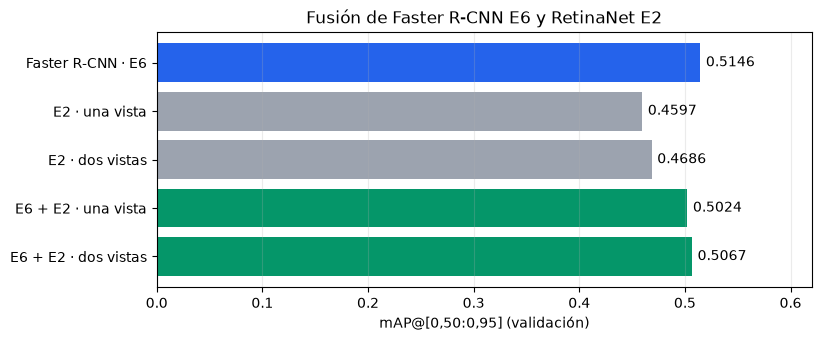

In [3]:
objetivos_val, entradas_val = cargar_particion("validation", (VISTA_UNICA, DOS_VISTAS))
metricas_val = {nombre: medir(preds, objetivos_val) for nombre, preds in entradas_val.items()}
for vista in (VISTA_UNICA, DOS_VISTAS):
    metricas_val[NOMBRES_ENSEMBLE[vista]] = evaluar_fusion("validation", vista, entradas_val, objetivos_val)

vista_elegida = max(NOMBRES_ENSEMBLE, key=lambda vista: metricas_val[NOMBRES_ENSEMBLE[vista]]["map"])
fusion_elegida = NOMBRES_ENSEMBLE[vista_elegida]
resultado_val = resumen(metricas_val)
display(resultado_val.style.format(precision=4))
print(f"Fusión seleccionada por mAP global en validación: {fusion_elegida}")

fig, ax = plt.subplots(figsize=(8.1, 3.3), layout="constrained")
colores = [
    "#2563eb" if nombre == NOMBRE_E6 else "#059669" if nombre in NOMBRES_ENSEMBLE.values() else "#9ca3af"
    for nombre in resultado_val.index
]
barras = ax.barh(resultado_val.index, resultado_val["mAP@[0.50:0.95]"], color=colores)
ax.bar_label(barras, fmt="%.4f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 0.62)
ax.set_xlabel("mAP@[0,50:0,95] (validación)")
ax.set_title("Fusión de Faster R-CNN E6 y RetinaNet E2")
ax.grid(axis="x", alpha=0.25)
fig.savefig(DIR_ENSEMBLES / "comparativa_validacion.png", dpi=180, bbox_inches="tight")
plt.show()

### Resultado en validación

**E6 solo conserva el mayor mAP global, 0,5146.** Las fusiones alcanzan 0,5024 con RetinaNet de una vista y 0,5067 con dos vistas. La segunda gana por 0,44 puntos porcentuales entre las fusiones y pasa a test. Queda 0,79 puntos por debajo de E6. Su mAP@0,75 también baja frente a E6, de 0,5917 a 0,5590.

Con confianza ≥ 0,50, la fusión de dos vistas reduce los falsos positivos de 38 a 24 y deja 162 anotaciones sin recuperar frente a 147 con E6. Con esta configuración de WBF hay un intercambio entre falsas alarmas y cobertura.

## 2. Evaluación final en test

Se vuelve a evaluar **la fusión seleccionada en validación**, con los mismos pesos y umbrales, junto con E6 y la variante de E2 que le sirve de entrada. La otra fusión queda documentada en validación.

In [4]:
objetivos_test, entradas_test = cargar_particion("test", (vista_elegida,))
metricas_test = {nombre: medir(preds, objetivos_test) for nombre, preds in entradas_test.items()}
metricas_test[fusion_elegida] = evaluar_fusion("test", vista_elegida, entradas_test, objetivos_test)
resultado_test = resumen(metricas_test)
display(resultado_test.style.format(precision=4))

,mAP@[0.50:0.95],mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,AP crack @ IoU 0.75,F1@0.5,TP,FP,FN
Configuración,,,,,,,,,,,,
Faster R-CNN · E6,0.4696,0.7615,0.5395,0.4417,0.6897,0.3680,0.3512,0.3366,0.7418,806,85,476
E2 · dos vistas,0.4348,0.7150,0.5123,0.4060,0.6531,0.3462,0.3051,0.3069,0.6913,719,79,563
E6 + E2 · dos vistas,0.4657,0.7635,0.5329,0.4375,0.6813,0.3697,0.3463,0.3312,0.7400,777,41,505


### Resultado en test

**La fusión de dos vistas obtiene 0,4657 de mAP global, frente a 0,4696 de E6.** La diferencia es de −0,39 puntos porcentuales. El mAP@0,50 sube de 0,7615 a 0,7635, mientras que el mAP@0,75 baja de 0,5395 a 0,5329 y el mAP_small de 0,4417 a 0,4375.

A confianza ≥ 0,50, los falsos positivos bajan de 85 a 41 y las omisiones suben de 476 a 505. El F1 pasa de 0,7418 a 0,7400. Con el mAP global como criterio principal, **conservamos E6**. El resultado se refiere a las dos fusiones con pesos 1:1 e IoU 0,55 probadas en validación.

## 3. Evaluación adicional de Faster R-CNN a 960 px

El checkpoint de Faster R-CNN con anchors originales y 20 épocas obtuvo el mayor mAP de los checkpoints individuales de esa arquitectura en validación. Aquí se compara su evaluación adicional en test con RetinaNet E2 a 960 px y 20 épocas. Ambos usan una vista y anchors originales. Cada checkpoint se seleccionó por mAP en validación.

In [5]:
rutas_individuales = {
    "Faster R-CNN · 960 px, 20 épocas": DIR_RESULTADOS / "faster_rcnn_resolucion_20ep" / "metricas_test_final.json",
    "RetinaNet · E2, 960 px, 20 épocas": DIR_ENTRADAS[VISTA_UNICA] / "metricas_test_final.json",
}
metricas_individuales = {}
for nombre, ruta in rutas_individuales.items():
    datos = json.loads(ruta.read_text(encoding="utf-8"))
    metricas_individuales[nombre] = datos.get("test", datos)
resultado_individuales = resumen(metricas_individuales)
display(resultado_individuales.style.format(precision=4))

,mAP@[0.50:0.95],mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,AP crack @ IoU 0.75,F1@0.5,TP,FP,FN
Configuración,,,,,,,,,,,,
"Faster R-CNN · 960 px, 20 épocas",0.4532,0.7368,0.5064,0.4244,0.6605,0.3576,0.3415,0.3267,0.7329,826,146,456
"RetinaNet · E2, 960 px, 20 épocas",0.4277,0.7051,0.4976,0.4006,0.6505,0.3373,0.2955,0.2924,0.6803,715,105,567


### Comparación de checkpoints individuales

Faster R-CNN alcanza **0,4532** de mAP global, **0,7368** a IoU 0,50 y **0,4244** en objetos pequeños. RetinaNet obtiene 0,4277, 0,7051 y 0,4006, respectivamente. En esta comparación de checkpoints de una vista a 960 px y 20 épocas, Faster R-CNN obtiene 2,55 puntos porcentuales más de mAP global.

Dentro de Faster R-CNN, **E3b (960 px con anchors ajustados y 12 épocas)** sigue siendo el checkpoint individual con mayor mAP global en test (0,4581). El nuevo checkpoint de 20 épocas sí obtiene un AP de `crack` algo mayor (0,3415 frente a 0,3373). [Resultados originales de Faster R-CNN](resultados_faster_rcnn.ipynb)